In [1]:
from pathlib import Path
import ast
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest, bootstrap
import yaml
from IPython.display import display

%matplotlib inline

SOURCE = Path('results/mvp')
OUTPUT = Path('results/analysis')
cwd = Path.cwd()
if not SOURCE.is_absolute():
    SOURCE = next((p / SOURCE for p in (cwd, *cwd.parents) if (p / SOURCE).is_dir()), cwd / SOURCE)
if not SOURCE.is_dir():
    raise FileNotFoundError(f'Не найдена папка {SOURCE}; задайте SOURCE или откройте kernel из репозитория.')
SOURCE = SOURCE.resolve()
if not OUTPUT.is_absolute():
    OUTPUT = SOURCE.parent.parent / OUTPUT
(OUTPUT / 'tables').mkdir(parents=True, exist_ok=True)
(OUTPUT / 'figures').mkdir(parents=True, exist_ok=True)
config = yaml.safe_load((SOURCE / 'config.yaml').read_text())
summary = json.loads((SOURCE / 'summary.json').read_text())
families = config['families']
frozen = {f: json.loads((SOURCE / 'decisions' / f / 'frozen.json').read_text()) for f in families}
metrics = ['choice0', 'choice1', 'select0', 'select1', 'T_correct', 'G_correct', 'R', 'preserve', 'success']
keys = ['family', 'split', 'index', 'scene_id', 'seed', 'contrast', 'condition', 'site', 'alpha', 'key']
episodes = pd.read_csv(SOURCE / 'episodes.csv', usecols=keys + metrics + ['choice', 'intervention_calls'], keep_default_na=False)
for c in metrics + ['index', 'scene_id', 'seed', 'alpha', 'choice', 'intervention_calls']:
    episodes[c] = pd.to_numeric(episodes[c], errors='coerce')
episodes['unknown'] = 1 - episodes.choice0 - episodes.choice1
episodes['factor_correct'] = np.where(episodes.family.str.startswith('T'), episodes.T_correct, episodes.G_correct)
episodes['other_correct'] = np.where(episodes.family.str.startswith('T'), episodes.G_correct, episodes.T_correct)
assert len(episodes) == summary['completed'] and episodes.key.is_unique
assert episodes.seed.eq(config['seed']).all()
assert episodes[metrics + ['unknown']].isin([0, 1]).all().all()
assert episodes.success.eq(episodes.T_correct * episodes.G_correct * episodes.R).all()
assert episodes.select1.eq(episodes.choice1 * episodes.preserve).all()
assert episodes.select0.eq(episodes.choice0 * episodes.preserve).all()
for f in families:
    a = set(episodes.loc[episodes.family.eq(f) & episodes.split.eq('development'), 'scene_id'])
    b = set(episodes.loc[episodes.family.eq(f) & episodes.split.eq('test'), 'scene_id'])
    assert not a & b
test = episodes[episodes.split.eq('test')].copy()
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.labelcolor': '#263244', 'text.color': '#263244', 'xtick.color': '#263244',
                     'ytick.color': '#263244', 'savefig.facecolor': 'white'})
family_labels = {'T_native': 'T · исходные объекты', 'G_native': 'G · исходные цели',
                 'T_color': 'T · цвет объектов', 'G_color': 'G · цвет целей'}
contrast_labels = {'text': 'Текст', 'visual': 'Изображение'}
colors = {'choice0': '#1E5A8A', 'choice1': '#C77524', 'unknown': '#D9DEE4'}
tables = {}

def table(name, frame, columns=None):
    tables[name] = frame.copy()
    frame.to_csv(OUTPUT / 'tables' / f'{name}.csv', index=False)
    view = frame if columns is None else frame[columns]
    display(view.style.hide(axis='index').format(precision=3, na_rep='—').set_caption(name))

def figure(name, fig):
    fig.savefig(OUTPUT / 'figures' / f'{name}.png', dpi=240, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def rows(family, contrast, condition, site='', alpha=1.0, split='test'):
    mask = (episodes.family.eq(family) & episodes.contrast.eq(contrast) & episodes.condition.eq(condition)
            & episodes.site.eq(site) & np.isclose(episodes.alpha, alpha) & episodes.split.eq(split))
    selected = episodes.loc[mask].set_index('scene_id').sort_index()
    assert selected.index.is_unique
    return selected

def interval(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        return np.nan, np.nan
    ci = bootstrap((values,), np.mean, method='percentile', n_resamples=config['bootstrap'],
                   rng=np.random.default_rng(config['seed'])).confidence_interval
    return float(ci.low), float(ci.high)

def effect(terms, metric):
    paired = pd.concat([weight * frame[metric] for weight, frame in terms], axis=1)
    complete = paired.dropna()
    delta = complete.sum(axis=1).to_numpy()
    low, high = interval(delta)
    return {'n': len(delta), 'excluded': len(paired) - len(delta),
            'delta_pp': 100 * delta.mean() if len(delta) else np.nan,
            'low_pp': 100 * low, 'high_pp': 100 * high}

family,expected,completed,status,steering_status,development_episodes,development_scenes,test_scenes
T_native,72,72,complete,skipped,161,8,12
G_native,132,132,complete,included,185,8,12
T_color,300,300,complete,included,346,8,12
G_color,240,240,complete,skipped,322,8,12


family,contrast,site,score_pp,selected,n_equal_max
T_native,text,backbone,50.000,True,2
G_native,text,backbone,81.250,True,2
T_color,text,dit_28,6.250,True,1
T_color,visual,dit_2,6.250,True,1
G_color,text,backbone,0.000,True,8
G_color,visual,backbone,0.000,True,8


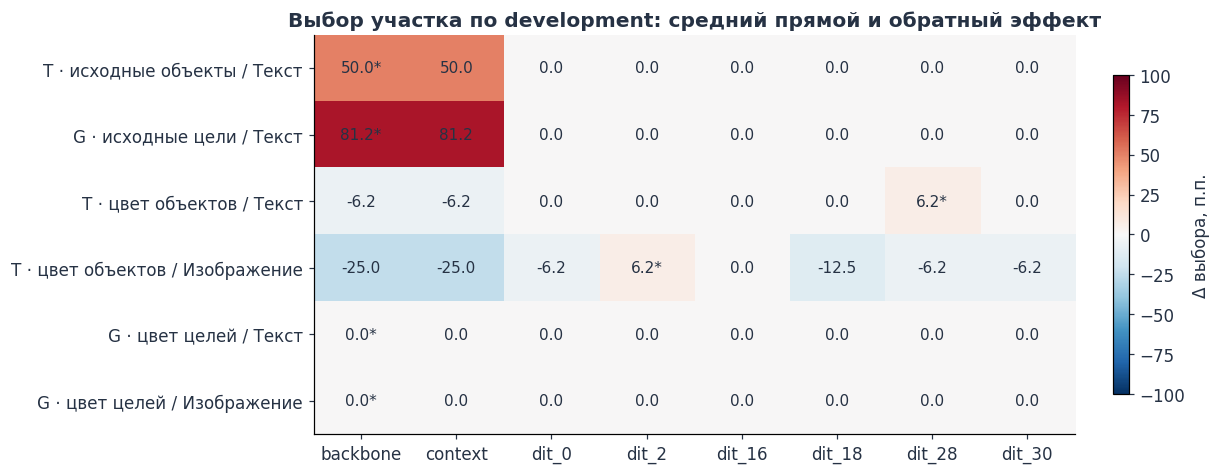

In [2]:
coverage = pd.DataFrame(summary['coverage'])[['family', 'expected', 'completed', 'status', 'steering_status']]
coverage['development_episodes'] = coverage.family.map(episodes[episodes.split.eq('development')].groupby('family').size())
coverage['development_scenes'] = coverage.family.map(episodes[episodes.split.eq('development')].groupby('family').scene_id.nunique())
coverage['test_scenes'] = coverage.family.map(test.groupby('family').scene_id.nunique())
assert coverage.status.eq('complete').all()
table('coverage', coverage)

selection = []
for f in families:
    for contrast, gate in frozen[f]['patches'].items():
        for site, score in gate['development_scores'].items():
            selection.append({'family': f, 'contrast': contrast, 'site': site, 'score_pp': 100 * score,
                              'selected': site == gate['site']})
development = pd.DataFrame(selection)
development['n_equal_max'] = development.groupby(['family', 'contrast']).score_pp.transform(lambda x: int(x.eq(x.max()).sum()))
table('development_selection', development[development.selected])
labels = [f'{family_labels[f]} / {contrast_labels[c]}' for f, c in development[['family', 'contrast']].drop_duplicates().itertuples(index=False)]
grid = development.pivot(index=['family', 'contrast'], columns='site', values='score_pp')
grid = grid.reindex(index=list(development[['family', 'contrast']].drop_duplicates().itertuples(index=False, name=None)), columns=config['sites'])
fig, ax = plt.subplots(figsize=(11, 4.2), layout='constrained')
im = ax.imshow(grid, cmap='RdBu_r', vmin=-100, vmax=100, aspect='auto')
for i, (f, c) in enumerate(grid.index):
    for j, site in enumerate(grid.columns):
        mark = '*' if frozen[f]['patches'][c]['site'] == site else ''
        ax.text(j, i, f'{grid.iloc[i, j]:.1f}{mark}', ha='center', va='center', fontsize=10)
ax.set(xticks=range(len(grid.columns)), xticklabels=grid.columns,
       yticks=range(len(labels)), yticklabels=labels, title='Выбор участка по development: средний прямой и обратный эффект')
fig.colorbar(im, ax=ax, label='Δ выбора, п.п.', shrink=.8)
figure('development_selection', fig)

family,contrast,condition,n,choice0,choice1,unknown,select1,R,success
G_color,mixed,mixedpatch_01,12,0.500,0.500,0.000,0.500,1.000,0.500
G_color,mixed,mixedpatch_11,12,0.500,0.500,0.000,0.500,1.000,0.500
G_color,mixed,mixedpatch_00,12,0.500,0.500,0.000,0.500,1.000,0.500
G_color,mixed,mixedpatch_10,12,0.500,0.500,0.000,0.500,1.000,0.500
G_color,mixed,mixed_01,12,0.500,0.500,0.000,0.500,1.000,0.500
G_color,mixed,mixed_11,12,0.500,0.500,0.000,0.500,1.000,0.500
G_color,mixed,mixed_10,12,0.500,0.500,0.000,0.500,1.000,0.500
G_color,mixed,mixed_00,12,0.500,0.500,0.000,0.500,1.000,0.500
G_color,visual,patch_to_base,12,0.500,0.500,0.000,0.500,1.000,0.500
G_color,visual,patch_same,12,0.500,0.500,0.000,0.500,1.000,0.500


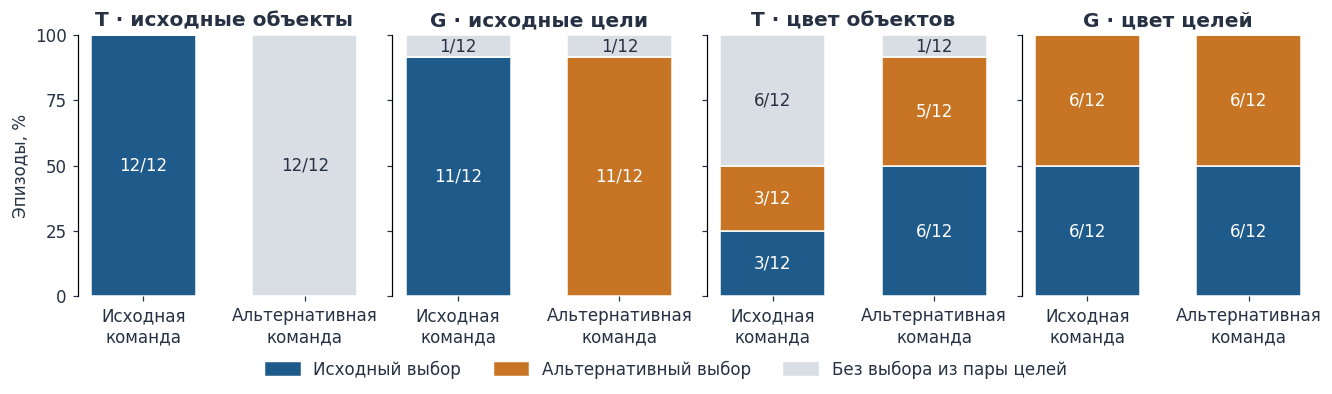

In [3]:
outcomes = test.groupby(['family', 'contrast', 'condition', 'site', 'alpha'], sort=False).agg(
    n=('key', 'size'), **{m: (m, 'mean') for m in metrics + ['unknown', 'factor_correct', 'other_correct']}).reset_index()
outcomes['choice1_count'] = (outcomes.choice1 * outcomes.n).round().astype(int)
outcomes['select1_count'] = (outcomes.select1 * outcomes.n).round().astype(int)
outcomes['active_fraction'] = test.groupby(['family', 'contrast', 'condition', 'site', 'alpha'], sort=False).intervention_calls.apply(lambda x: x.gt(0).mean()).to_numpy()
outcomes['choice1_wilson_low'], outcomes['choice1_wilson_high'] = zip(*[
    binomtest(int(r.choice1_count), int(r.n)).proportion_ci(method='wilson') for r in outcomes.itertuples()])
table('test_outcomes', outcomes, ['family', 'contrast', 'condition', 'n', 'choice0', 'choice1', 'unknown', 'select1', 'R', 'success'])
baseline = outcomes[outcomes.contrast.eq('text') & outcomes.condition.isin(['baseline', 'alternate'])].copy()
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), sharey=True, layout='constrained')
for ax, f in zip(axes, families):
    sub = baseline[baseline.family.eq(f)].set_index('condition').reindex(['baseline', 'alternate'])
    bottom = np.zeros(2)
    for metric in ['choice0', 'choice1', 'unknown']:
        values = sub[metric].to_numpy() * 100
        ax.bar([0, 1], values, bottom=bottom, color=colors[metric], width=.65, edgecolor='white', linewidth=1)
        for i, value in enumerate(values):
            if value >= 8:
                n = int(sub.n.iloc[i])
                ax.text(i, bottom[i] + value / 2, f'{int(round(value * n / 100))}/{n}', ha='center', va='center',
                        color='white' if metric != 'unknown' else '#263244', fontsize=11)
        bottom += values
    ax.set(xticks=[0, 1], xticklabels=['Исходная\nкоманда', 'Альтернативная\nкоманда'],
           ylim=(0, 100), title=family_labels[f])
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.spines['bottom'].set_visible(False)
axes[0].set_ylabel('Эпизоды, %')
fig.legend([plt.Rectangle((0, 0), 1, 1, color=colors[m]) for m in colors],
           ['Исходный выбор', 'Альтернативный выбор', 'Без выбора из пары целей'],
           loc='outside lower center', ncol=3, frameon=False)
figure('baseline_choices', fig)

family,contrast,site,forward_n,forward_delta_pp,forward_low_pp,forward_high_pp,reverse_delta_pp,Y1_delta_pp,R_delta_pp,other_delta_pp
T_native,text,backbone,12,0.000,0.000,0.000,100.000,0.000,-100.000,-100.000
G_native,text,backbone,12,83.333,58.333,100.000,83.333,83.333,0.000,0.000
T_color,text,dit_28,12,25.000,0.000,50.000,-8.333,16.667,16.667,16.667
T_color,visual,dit_2,12,16.667,0.000,41.667,0.000,0.000,-8.333,0.000
G_color,text,backbone,12,0.000,0.000,0.000,0.000,0.000,0.000,0.000
G_color,visual,backbone,12,0.000,0.000,0.000,0.000,0.000,0.000,0.000


family,contrast,control,choice1_delta_pp,choice1_low_pp,choice1_high_pp
T_native,text,patch_same,0.000,0.000,0.000
T_native,text,patch_random,0.000,0.000,0.000
G_native,text,patch_same,83.333,58.333,100.000
G_native,text,patch_random,83.333,58.333,100.000
T_color,text,patch_same,8.333,0.000,25.000
T_color,text,patch_random,16.667,0.000,41.667
T_color,visual,patch_same,0.000,0.000,0.000
T_color,visual,patch_random,0.000,-25.000,25.000
G_color,text,patch_same,0.000,0.000,0.000
G_color,text,patch_random,0.000,0.000,0.000


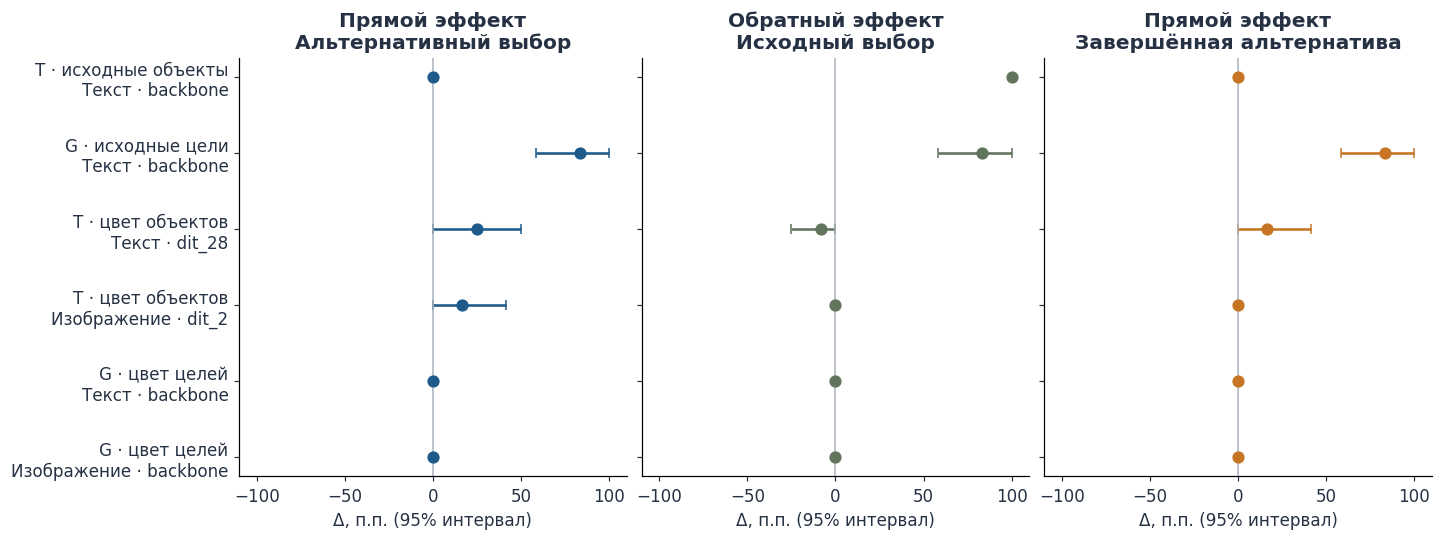

In [4]:
patch_data, control_data = [], []
for f in families:
    for c, gate in frozen[f]['patches'].items():
        site = gate['site']
        base, alt = rows(f, c, 'baseline'), rows(f, c, 'alternate')
        forward, reverse = rows(f, c, 'patch_to_alt', site), rows(f, c, 'patch_to_base', site)
        result = {'family': f, 'contrast': c, 'site': site}
        for label, pair, metric in [('forward', [(1, forward), (-1, base)], 'choice1'),
                                    ('reverse', [(1, reverse), (-1, alt)], 'choice0'),
                                    ('Y1', [(1, forward), (-1, base)], 'select1'),
                                    ('Y0_reverse', [(1, reverse), (-1, alt)], 'select0'),
                                    ('R', [(1, forward), (-1, base)], 'R'),
                                    ('other', [(1, forward), (-1, base)], 'other_correct'),
                                    ('SR', [(1, forward), (-1, base)], 'success')]:
            result.update({f'{label}_{k}': v for k, v in effect(pair, metric).items()})
        patch_data.append(result)
        for control in ['patch_same', 'patch_random']:
            rec = {'family': f, 'contrast': c, 'site': site, 'control': control}
            comparator = rows(f, c, control, site)
            for label, metric in [('choice1', 'choice1'), ('Y1', 'select1'), ('R', 'R')]:
                rec.update({f'{label}_{k}': v for k, v in effect([(1, forward), (-1, comparator)], metric).items()})
            control_data.append(rec)
patch = pd.DataFrame(patch_data)
controls = pd.DataFrame(control_data)
table('patch_effects', patch, ['family', 'contrast', 'site', 'forward_n', 'forward_delta_pp', 'forward_low_pp',
                              'forward_high_pp', 'reverse_delta_pp', 'Y1_delta_pp', 'R_delta_pp', 'other_delta_pp'])
table('patch_controls', controls, ['family', 'contrast', 'control', 'choice1_delta_pp', 'choice1_low_pp', 'choice1_high_pp'])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True, layout='constrained')
labels = [f'{family_labels[r.family]}\n{contrast_labels[r.contrast]} · {r.site}' for r in patch.itertuples()]
for ax, metric, title, color in zip(axes, ['forward', 'reverse', 'Y1'],
        ['Прямой эффект\nАльтернативный выбор', 'Обратный эффект\nИсходный выбор', 'Прямой эффект\nЗавершённая альтернатива'],
        ['#1E5A8A', '#61745C', '#C77524']):
    for i, row in patch.iterrows():
        x, low, high = [row[f'{metric}_{k}'] for k in ['delta_pp', 'low_pp', 'high_pp']]
        ax.errorbar(x, i, xerr=[[x - low], [high - x]], fmt='o', color=color, ms=7, capsize=3, lw=1.7)
    ax.axvline(0, color='#A8B1BA', lw=1)
    ax.set(xlim=(-110, 110), xticks=[-100, -50, 0, 50, 100], title=title, xlabel='Δ, п.п. (95% интервал)')
axes[0].set(yticks=range(len(labels)), yticklabels=labels)
axes[0].invert_yaxis()
figure('patch_effects', fig)

family,included,site,alpha,sources,phase
T_native,False,—,—,0,не выполнен
G_native,True,backbone,1.000,8,после захвата
T_color,True,dit_28,0.500,8,до захвата
G_color,False,—,—,0,не выполнен


family,site,alpha,reference,choice1_n,choice1_delta_pp,choice1_low_pp,choice1_high_pp,Y1_delta_pp,R_delta_pp
G_native,backbone,1.000,baseline,12,83.333,58.333,100.000,83.333,0.000
G_native,backbone,1.000,steer_minus,12,83.333,58.333,100.000,83.333,0.000
G_native,backbone,1.000,steer_zero,12,83.333,58.333,100.000,83.333,0.000
G_native,backbone,1.000,steer_same,12,83.333,58.333,100.000,83.333,0.000
G_native,backbone,1.000,steer_random,12,83.333,58.333,100.000,83.333,0.000
T_color,dit_28,0.500,baseline,12,16.667,0.000,41.667,8.333,8.333
T_color,dit_28,0.500,steer_minus,12,8.333,0.000,25.000,8.333,8.333
T_color,dit_28,0.500,steer_zero,12,16.667,0.000,41.667,8.333,8.333
T_color,dit_28,0.500,steer_same,12,8.333,-16.667,33.333,0.000,8.333
T_color,dit_28,0.500,steer_random,12,0.000,-25.000,25.000,8.333,8.333


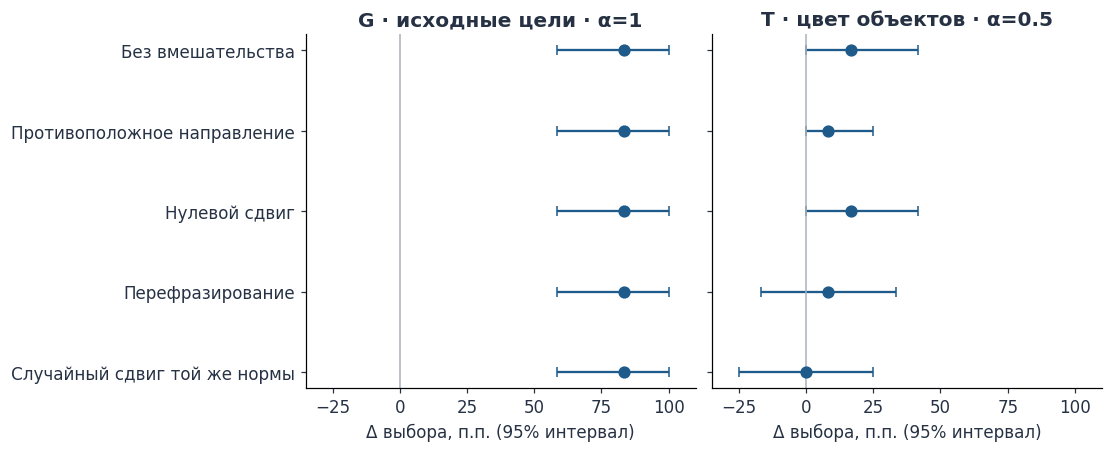

In [5]:
steering_data, steering_status = [], []
for f in families:
    gate = frozen[f]['steering']
    included = gate.get('alpha') is not None
    steering_status.append({'family': f, 'included': included, 'site': gate.get('site'),
                            'alpha': gate.get('alpha'), 'sources': gate.get('source_count', 0),
                            'phase': 'после захвата' if included and f.startswith('G') else 'до захвата' if included else 'не выполнен'})
    if not included:
        continue
    site, alpha = gate['site'], gate['alpha']
    steered = rows(f, 'text', 'steer', site, alpha)
    for reference in ['baseline', 'steer_minus', 'steer_zero', 'steer_same', 'steer_random']:
        comparison = rows(f, 'text', reference, '' if reference == 'baseline' else site,
                          1.0 if reference == 'baseline' else alpha)
        result = {'family': f, 'site': site, 'alpha': alpha, 'reference': reference}
        for label, metric in [('choice1', 'choice1'), ('Y1', 'select1'), ('R', 'R'), ('other', 'other_correct')]:
            result.update({f'{label}_{k}': v for k, v in effect([(1, steered), (-1, comparison)], metric).items()})
        steering_data.append(result)
steering = pd.DataFrame(steering_data)
table('steering_status', pd.DataFrame(steering_status))
table('steering_effects', steering, ['family', 'site', 'alpha', 'reference', 'choice1_n', 'choice1_delta_pp',
                                   'choice1_low_pp', 'choice1_high_pp', 'Y1_delta_pp', 'R_delta_pp'])
if not steering.empty:
    included = steering.family.drop_duplicates().tolist()
    fig, axes = plt.subplots(1, len(included), figsize=(10, 4.0), sharey=True, squeeze=False, layout='constrained')
    reference_labels = {'baseline': 'Без вмешательства', 'steer_minus': 'Противоположное направление',
                        'steer_zero': 'Нулевой сдвиг', 'steer_same': 'Перефразирование', 'steer_random': 'Случайный сдвиг той же нормы'}
    for ax, f in zip(axes[0], included):
        sub = steering[steering.family.eq(f)]
        for i, r in enumerate(sub.itertuples()):
            ax.errorbar(r.choice1_delta_pp, i, xerr=[[r.choice1_delta_pp-r.choice1_low_pp],
                         [r.choice1_high_pp-r.choice1_delta_pp]], fmt='o', ms=7, color='#1E5A8A', capsize=3)
        ax.axvline(0, color='#A8B1BA', lw=1)
        ax.set(xlim=(-35, 110), xticks=[-25, 0, 25, 50, 75, 100],
               yticks=range(len(sub)), yticklabels=[reference_labels[r] for r in sub.reference],
               xlabel='Δ выбора, п.п. (95% интервал)', title=f'{family_labels[f]} · α={sub.alpha.iloc[0]:g}')
    axes[0, 0].invert_yaxis()
    figure('steering_controls', fig)

In [6]:
transition_rows=[]
for f in families:
    comparisons=[(c,'patch_to_alt',gate['site'],1.0) for c,gate in frozen[f]['patches'].items()]
    gate=frozen[f]['steering']
    if gate.get('alpha') is not None:
        comparisons.append(('text','steer',gate['site'],gate['alpha']))
    for c,condition,site,alpha in comparisons:
        base=rows(f,c,'baseline')
        changed=rows(f,c,condition,site,alpha)
        paired=base[['choice0','choice1','unknown','R']].join(changed[['choice0','choice1','unknown','R']],
                                                          lsuffix='_base',rsuffix='_edit',how='inner')
        n=len(paired)
        switch=int((paired.choice0_base.eq(1)&paired.choice1_edit.eq(1)).sum())
        emerged=int((paired.unknown_base.eq(1)&paired.choice1_edit.eq(1)).sum())
        lost=int((paired.choice1_base.eq(1)&paired.choice1_edit.eq(0)).sum())
        ci=binomtest(switch,n).proportion_ci(method='wilson') if n else [np.nan,np.nan]
        transition_rows.append({'family':f,'contrast':c,'condition':condition,'site':site,'alpha':alpha,'n':n,
                                'original_to_alternative':switch,'unknown_to_alternative':emerged,
                                'alternative_lost':lost,'switch_rate':switch/n if n else np.nan,
                                'switch_wilson_low':ci[0],'switch_wilson_high':ci[1],
                                'R_lost':int((paired.R_base.eq(1)&paired.R_edit.eq(0)).sum()),
                                'R_gained':int((paired.R_base.eq(0)&paired.R_edit.eq(1)).sum())})
transitions=pd.DataFrame(transition_rows)
table('choice_transitions',transitions)

family,contrast,condition,site,alpha,n,original_to_alternative,unknown_to_alternative,alternative_lost,switch_rate,switch_wilson_low,switch_wilson_high,R_lost,R_gained
T_native,text,patch_to_alt,backbone,1.000,12,0,0,0,0.000,0.000,0.242,12,0
G_native,text,patch_to_alt,backbone,1.000,12,10,0,0,0.833,0.552,0.953,0,0
G_native,text,steer,backbone,1.000,12,10,0,0,0.833,0.552,0.953,0,0
T_color,text,patch_to_alt,dit_28,1.000,12,0,3,0,0.000,0.000,0.242,1,3
T_color,visual,patch_to_alt,dit_2,1.000,12,0,2,0,0.000,0.000,0.242,1,0
T_color,text,steer,dit_28,0.500,12,0,2,0,0.000,0.000,0.242,0,1
G_color,text,patch_to_alt,backbone,1.000,12,0,0,0,0.000,0.000,0.242,0,0
G_color,visual,patch_to_alt,backbone,1.000,12,0,0,0,0.000,0.000,0.242,0,0


family,series,bits,n,desired_choice,choice0,choice1,unknown,binding_correct,select1,R,success,physical0,physical1
T_color,inputs,00,12,0,0.250,0.250,0.500,0.250,0.250,0.500,0.250,0.500,0.000
T_color,inputs,10,12,1,0.500,0.417,0.083,0.417,0.417,0.833,0.417,0.917,0.000
T_color,inputs,01,12,1,0.417,0.250,0.333,0.250,0.083,0.333,0.083,0.667,0.000
T_color,inputs,11,12,0,0.500,0.417,0.083,0.500,0.417,0.833,0.417,0.917,0.000
T_color,context_patch,00,12,0,0.250,0.250,0.500,0.250,0.250,0.500,0.250,0.500,0.000
T_color,context_patch,10,12,1,0.500,0.417,0.083,0.417,0.417,0.833,0.417,0.917,0.000
T_color,context_patch,01,12,1,0.417,0.250,0.333,0.250,0.083,0.333,0.250,0.667,0.000
T_color,context_patch,11,12,0,0.500,0.417,0.083,0.500,0.333,0.750,0.417,0.917,0.000
G_color,inputs,00,12,0,0.500,0.500,0.000,0.500,0.500,1.000,0.500,1.000,0.000
G_color,inputs,10,12,1,0.500,0.500,0.000,0.500,0.500,1.000,0.500,1.000,0.000


family,series,change,n,excluded,known_both,physical_flip_count,physical_flip_rate,flip_wilson_low,flip_wilson_high,both_correct_count,both_correct_rate
T_color,inputs,text_swap,12,0,5,0,0.000,0.000,0.242,0,0.000
T_color,inputs,visual_swap,12,0,6,0,0.000,0.000,0.242,0,0.000
T_color,inputs,both_swap,12,0,6,0,0.000,0.000,0.242,3,0.250
T_color,context_patch,text_swap,12,0,5,0,0.000,0.000,0.242,0,0.000
T_color,context_patch,visual_swap,12,0,6,0,0.000,0.000,0.242,0,0.000
T_color,context_patch,both_swap,12,0,6,0,0.000,0.000,0.242,3,0.250
G_color,inputs,text_swap,12,0,12,0,0.000,0.000,0.242,0,0.000
G_color,inputs,visual_swap,12,0,12,0,0.000,0.000,0.242,0,0.000
G_color,inputs,both_swap,12,0,12,0,0.000,0.000,0.242,6,0.500
G_color,context_patch,text_swap,12,0,12,0,0.000,0.000,0.242,0,0.000


family,series,metric,n,excluded,delta_pp,low_pp,high_pp
T_color,inputs,choice1,12,0,0.000,-25.000,25.000
T_color,inputs,select1,12,0,16.667,-16.667,50.000
T_color,inputs,binding_correct,12,0,8.333,-75.000,91.667
T_color,context_patch,choice1,12,0,0.000,-25.000,25.000
T_color,context_patch,select1,12,0,8.333,-25.000,41.667
T_color,context_patch,binding_correct,12,0,8.333,-75.000,91.667
G_color,inputs,choice1,12,0,0.000,0.000,0.000
G_color,inputs,select1,12,0,0.000,0.000,0.000
G_color,inputs,binding_correct,12,0,0.000,-100.000,100.000
G_color,context_patch,choice1,12,0,0.000,0.000,0.000


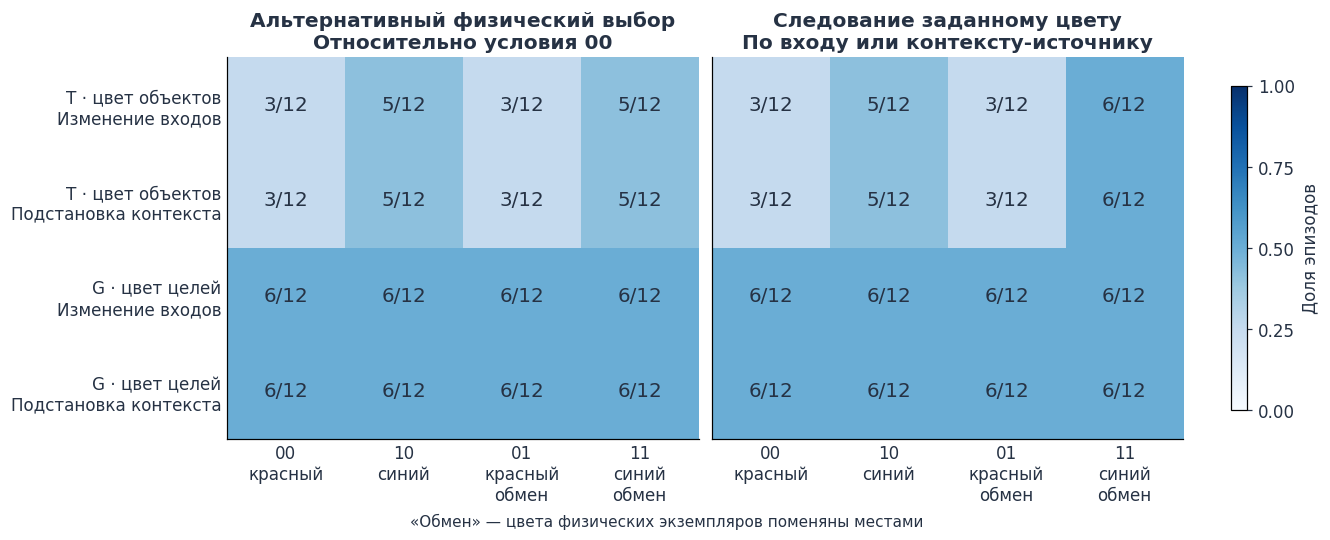

In [7]:
mixed_rows, response_rows, interaction_rows = [], [], []
for f in [f for f in families if f.endswith('color')]:
    for series, prefix, site in [('inputs', 'mixed_', ''), ('context_patch', 'mixedpatch_', 'context')]:
        groups = {bits: rows(f, 'mixed', prefix + bits, site).copy() for bits in ['00', '10', '01', '11']}
        for bits, group in groups.items():
            desired = int(bits[0]) ^ int(bits[1])
            group['binding_correct'] = group.choice1 if desired else group.choice0
            if series == 'inputs':
                assert group.binding_correct.eq(group.factor_correct).all()
            mixed_rows.append({'family': f, 'series': series, 'bits': bits, 'n': len(group),
                               'desired_choice': desired, **{m: group[m].mean() for m in
                               ['choice0', 'choice1', 'unknown', 'binding_correct', 'select1', 'R', 'success']},
                               'physical0': group.choice.eq(0).mean(), 'physical1': group.choice.eq(1).mean()})
        for kind, left, right in [('text_swap', '00', '10'), ('visual_swap', '00', '01'), ('both_swap', '00', '11')]:
            pair = pd.concat([groups[left].choice, groups[right].choice], axis=1).dropna()
            all_scenes = set(groups[left].index) | set(groups[right].index)
            complete = set(groups[left].index) & set(groups[right].index)
            changed = int(pair.iloc[:, 0].ne(pair.iloc[:, 1]).sum())
            n = len(complete)
            ci = binomtest(changed, n).proportion_ci(method='wilson') if n else [np.nan, np.nan]
            a, b = groups[left].binding_correct.reindex(sorted(complete)), groups[right].binding_correct.reindex(sorted(complete))
            response_rows.append({'family': f, 'series': series, 'change': kind, 'n': n,
                                  'excluded': len(all_scenes)-n, 'known_both': len(pair), 'physical_flip_count': changed,
                                  'physical_flip_rate': changed/n if n else np.nan, 'flip_wilson_low': ci[0], 'flip_wilson_high': ci[1],
                                  'both_correct_count': int((a.eq(1) & b.eq(1)).sum()),
                                  'both_correct_rate': (a.eq(1) & b.eq(1)).mean() if n else np.nan})
        for metric in ['choice1', 'select1', 'binding_correct']:
            terms = [(1, groups['11']), (-1, groups['10']), (-1, groups['01']), (1, groups['00'])]
            interaction_rows.append({'family': f, 'series': series, 'metric': metric, **effect(terms, metric)})
mixed = pd.DataFrame(mixed_rows)
responses = pd.DataFrame(response_rows)
interactions = pd.DataFrame(interaction_rows)
table('color_conditions', mixed)
table('color_paired_response', responses)
table('mixed_interactions', interactions)
if not mixed.empty:
    row_order = [(f, s) for f in families if f.endswith('color') for s in ['inputs', 'context_patch']]
    labels = [f'{family_labels[f]}\n'+('Изменение входов' if s == 'inputs' else 'Подстановка контекста') for f, s in row_order]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout='constrained')
    for ax, metric, title in zip(axes, ['choice1', 'binding_correct'],
                                ['Альтернативный физический выбор\nОтносительно условия 00', 'Следование заданному цвету\nПо входу или контексту-источнику']):
        grid = mixed.pivot(index=['family', 'series'], columns='bits', values=metric).reindex(index=row_order, columns=['00','10','01','11'])
        im = ax.imshow(grid, cmap='Blues', vmin=0, vmax=1, aspect='auto')
        for i in range(len(grid)):
            for j in range(4):
                v = grid.iloc[i,j]
                n = int(mixed[(mixed.family==row_order[i][0])&(mixed.series==row_order[i][1])].n.iloc[0])
                ax.text(j,i,f'{int(round(v*n))}/{n}',ha='center',va='center',fontsize=13,color='white' if v>.6 else '#263244')
        ax.set(xticks=range(4), xticklabels=['00\nкрасный', '10\nсиний', '01\nкрасный\nобмен', '11\nсиний\nобмен'],
               yticks=range(len(labels)), yticklabels=labels, title=title)
        ax.tick_params(length=0)
    fig.colorbar(im, ax=axes, label='Доля эпизодов', ticks=[0,.25,.5,.75,1], shrink=.85)
    fig.supxlabel('«Обмен» — цвета физических экземпляров поменяны местами',fontsize=10)
    figure('color_binding', fig)

family,site,modality,contrast,cka,shuffled,n,source
T_native,backbone,text,text,0.998,-0.175,8,cka.json
T_native,backbone,image,text,1.000,-0.155,8,cka.json
T_native,context,text,text,0.991,0.057,8,cka.json
T_native,context,image,text,0.986,-0.078,8,cka.json
T_native,dit_0,action,text,0.967,-0.071,8,cka.json
T_native,dit_2,action,text,0.908,0.030,8,cka.json
T_native,dit_16,action,text,0.914,-0.194,8,cka.json
T_native,dit_18,action,text,0.934,0.175,8,cka.json
T_native,dit_28,action,text,0.957,-0.144,8,cka.json
T_native,dit_30,action,text,0.957,0.099,8,cka.json


family,site,modality,n_total,n_valid,cosine,low,high
T_color,backbone,text,8,8,0.752,0.704,0.798
T_color,backbone,image,8,0,—,—,—
T_color,context,text,8,8,0.542,0.460,0.621
T_color,context,image,8,8,0.218,0.144,0.286
T_color,dit_0,action,8,8,0.320,0.171,0.472
T_color,dit_2,action,8,8,0.169,-0.066,0.395
T_color,dit_16,action,8,8,0.197,0.081,0.314
T_color,dit_18,action,8,8,0.157,0.017,0.305
T_color,dit_28,action,8,8,0.114,-0.122,0.338
T_color,dit_30,action,8,8,0.070,-0.232,0.351


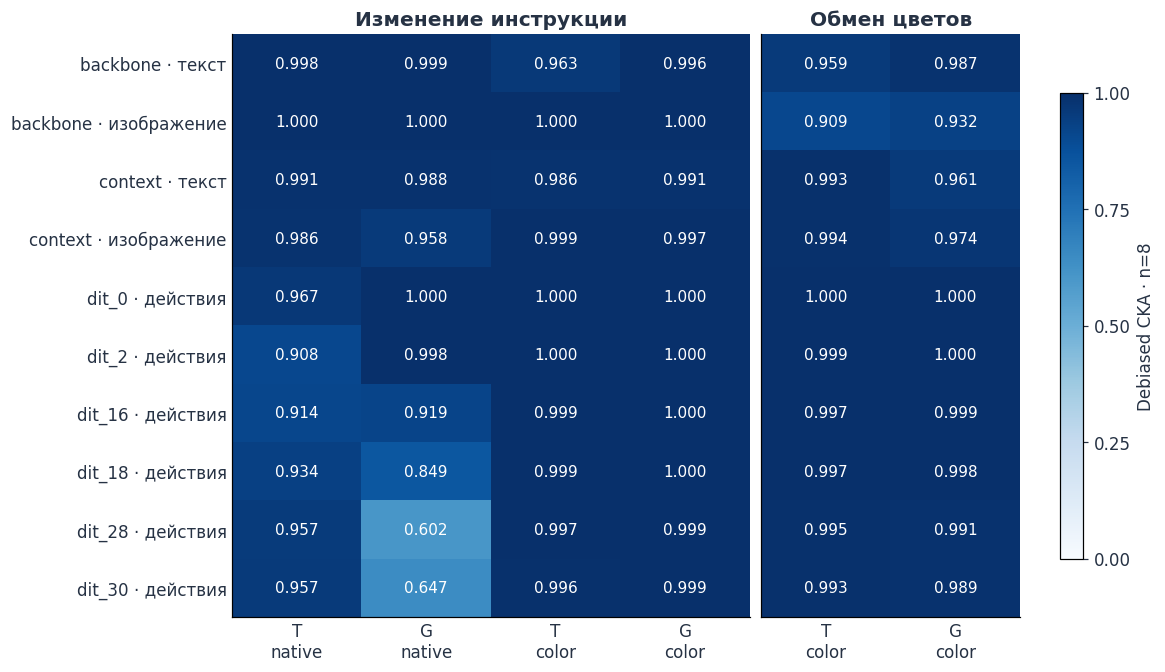

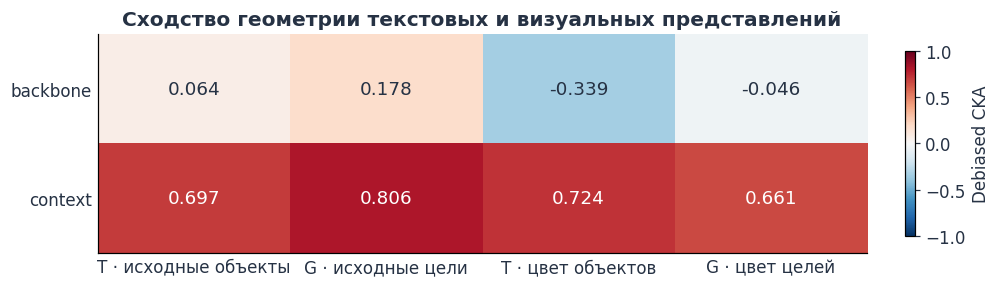

In [8]:
cka_rows, cosine_rows = [], []
for f in families:
    folder = SOURCE / 'diagnostics' / f
    saved = json.loads((folder/'cka.json').read_text())
    for pair, values in saved.items():
        assert values['estimator'] == 'debiased_linear_hsic_u'
        left, right = pair.split(' vs ')
        score = values['cka']
        site, modality, _ = left.split('/')
        kind = 'crossmodal' if right.endswith('/base') else right.split('/')[-1]
        cka_rows.append({'family': f, 'site': site, 'modality': modality, 'contrast': kind,
                         'cka': score, 'shuffled': values['shuffled'], 'n': values['n'], 'source': 'cka.json'})
    if (folder/'cosine.json').is_file():
        for pair, values in json.loads((folder/'cosine.json').read_text()).items():
            valid = [x for x in values['per_scene'] if x is not None and np.isfinite(x)]
            low, high = interval(valid)
            site, modality, _ = pair.split('/')
            cosine_rows.append({'family': f, 'site': site, 'modality': modality, 'n_total': len(values['per_scene']),
                                'n_valid': len(valid), 'cosine': np.mean(valid) if valid else np.nan, 'low': low, 'high': high})
cka = pd.DataFrame(cka_rows)
cosine = pd.DataFrame(cosine_rows)
table('debiased_cka', cka)
table('text_visual_cosine', cosine)
representation_order = [('backbone','text'),('backbone','image'),('context','text'),('context','image')]
representation_order += [(s, 'action') for s in config['sites'] if s.startswith('dit_')]
representation_labels = [s+' · '+{'text':'текст','image':'изображение','action':'действия'}[m] for s,m in representation_order]
fig, axes = plt.subplots(1,2,figsize=(10.5,6.0),gridspec_kw={'width_ratios':[2,1]},sharey=True,layout='constrained')
for ax, contrast in zip(axes,['text','visual']):
    cols = families if contrast == 'text' else [f for f in families if f.endswith('color')]
    grid = cka[cka.contrast.eq(contrast)].pivot(index=['site','modality'],columns='family',values='cka').reindex(index=representation_order,columns=cols)
    im = ax.imshow(np.ma.masked_invalid(grid.to_numpy()),cmap='Blues',vmin=0,vmax=1,aspect='auto')
    for i in range(len(grid)):
        for j in range(len(cols)):
            v = grid.iloc[i,j]
            ax.text(j,i,'—' if pd.isna(v) else f'{v:.3f}',ha='center',va='center',color='white' if v>.6 else '#263244',fontsize=10)
    ax.set(xticks=range(len(cols)),xticklabels=[f.replace('_','\n') for f in cols],yticks=range(len(grid)),yticklabels=representation_labels,
           title='Изменение инструкции' if contrast=='text' else 'Обмен цветов')
    ax.tick_params(length=0)
fig.colorbar(im,ax=axes,label=f'Debiased CKA · n={int(cka.n.min())}',ticks=[0,.25,.5,.75,1],shrink=.8)
figure('cka_input_contrasts',fig)
crossmodal = cka[cka.contrast.eq('crossmodal')].pivot(index='site',columns='family',values='cka').reindex(index=['backbone','context'],columns=families)
fig,ax=plt.subplots(figsize=(9,2.5),layout='constrained')
im=ax.imshow(crossmodal,cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
for i in range(2):
    for j in range(len(families)):
        v=crossmodal.iloc[i,j]
        ax.text(j,i,f'{v:.3f}',ha='center',va='center',color='white' if abs(v)>.65 else '#263244',fontsize=12)
ax.set(xticks=range(len(families)),xticklabels=[family_labels[f] for f in families],yticks=[0,1],yticklabels=['backbone','context'],
       title='Сходство геометрии текстовых и визуальных представлений')
ax.tick_params(length=0)
fig.colorbar(im,ax=ax,label='Debiased CKA',ticks=[-1,-.5,0,.5,1],shrink=.85)
figure('cka_crossmodal',fig)

In [9]:
source_effects=pd.read_csv(SOURCE/'effects.csv',keep_default_na=False)
for r in source_effects[source_effects.split.eq('test') & source_effects.scenes.gt(0)].itertuples():
    terms=ast.literal_eval(r.terms)
    parts=[]
    for weight,selector in terms:
        mask=episodes.family.eq(r.family) & episodes.split.eq(r.split) & episodes.contrast.eq(r.contrast)
        for key,value in selector.items():
            mask &= episodes[key].eq(value)
        group=episodes[mask].set_index('scene_id').sort_index()
        assert group.index.is_unique
        parts.append(weight*group[r.metric])
    values=pd.concat(parts,axis=1).dropna().sum(axis=1)
    assert len(values)==r.scenes and np.isclose(values.mean(),float(r.estimate),atol=1e-12)
for f in families:
    for c,gate in frozen[f]['patches'].items():
        a=rows(f,c,'baseline',split='development')
        b=rows(f,c,'patch_self',gate['site'],split='development')
        common=a.index.intersection(b.index)
        if len(common):
            assert a.loc[common,metrics].equals(b.loc[common,metrics])
    gate=frozen[f]['steering']
    if gate.get('alpha') is not None:
        a=rows(f,'text','baseline')
        b=rows(f,'text','steer_zero',gate['site'],gate['alpha'])
        assert a[metrics].equals(b[metrics])